# Pump scheduling with exact gradients (`difflow_water.network`)

EPANET's example network 1 runs its pump on tank-level controls: on when the tank drops below 110 ft, off above 140 ft. Here the controls are replaced by a schedule, the pump's speed in twelve two-hour blocks, chosen to minimize the day's energy cost under a time-of-use tariff while keeping the tank inside its operating band and ending the day at least as full as it started.

The simulation is `difflow_water.network.simulate` (EPANET 2.2's hydraulics and time stepping; it reproduces EPANET's run of this network to 0.1 mm of tank level). Gradients of cost and tank levels with respect to the twelve speeds come from replaying each run's `plan` in JAX, so SLSQP gets exact derivatives.

The tariff and the operating band are ILLUSTRATIVE.

In [1]:
import copy
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from difflow_water.network import NetworkModel, example_inp, read_inp, simulate

net, sched = read_inp(example_inp("Net1"))
model = NetworkModel(net)
ip = model.arrays.links.index("9")
tank = net.tanks["2"]
print(f"tank 2: level {tank.level:.2f} m, band {tank.min_level:.2f}-{tank.max_level:.2f} m")

def price(t):                          # USD/kWh, ILLUSTRATIVE time-of-use tariff
    h = (t / 3600.0) % 24
    return np.where((h >= 7) & (h < 19), 0.20, 0.08)

tank 2: level 36.58 m, band 30.48-45.72 m


## The baseline: EPANET's level controls

In [2]:
base = simulate(net, sched, model=model)
base_cost = float(jnp.sum(jnp.asarray(price(base["step_time"])) * base["step_power"][:, ip] * base["step_dt"]) / 3.6e6)
print(f"baseline (level controls): {float(base['pump_energy_kwh'][ip]):.0f} kWh, cost {base_cost:.2f} USD")

baseline (level controls): 1333 kWh, cost 170.87 USD


## The schedule

Speeds in [0, 1.2] (0 is off: the pump's head gain no longer opens its check valve). Constraints: tank level at every hour within 0.3 m of the band, final level >= initial level. Each evaluation runs the day once to record its plan, then `jax.jacfwd` replays the plan for the derivatives of the cost and of the 25 hourly levels with respect to the 12 speeds.

In [3]:
sched_free = copy.deepcopy(sched)
sched_free.controls = []
n_blocks, block = 12, 7200.0
margin = 0.3

def profile(s):
    return jnp.ones((n_blocks, model.arrays.n_links)).at[:, ip].set(s)

def outputs(s, plan=None):
    run = simulate(net, sched_free, model=model, speed_profile=profile(s), profile_step=block, plan=plan)
    cost = jnp.sum(jnp.asarray(price(run["step_time"])) * run["step_power"][:, ip] * run["step_dt"]) / 3.6e6
    return jnp.concatenate([cost[None], run["tank_level"][:, 0]]), run["plan"]

cache = {}
def evaluate(x):
    key = tuple(np.round(x, 12))
    if key not in cache:
        y, plan = outputs(jnp.asarray(x))
        J = jax.jacfwd(lambda s: outputs(s, plan)[0])(jnp.asarray(x))
        cache.clear()
        cache[key] = (np.asarray(y), np.asarray(J))
    return cache[key]

lo, hi, L0 = tank.min_level + margin, tank.max_level - margin, tank.level
cons = [
    {"type": "ineq", "fun": lambda x: evaluate(x)[0][1:] - lo, "jac": lambda x: evaluate(x)[1][1:]},
    {"type": "ineq", "fun": lambda x: hi - evaluate(x)[0][1:], "jac": lambda x: -evaluate(x)[1][1:]},
    {"type": "ineq", "fun": lambda x: evaluate(x)[0][-1:] - L0, "jac": lambda x: evaluate(x)[1][-1:]},
]
x0 = np.full(n_blocks, 1.0)
res = minimize(lambda x: evaluate(x)[0][0], x0, jac=lambda x: evaluate(x)[1][0], method="SLSQP",
               bounds=[(0.0, 1.2)] * n_blocks, constraints=cons, options={"maxiter": 200})
print(res.message, f"after {res.nit} iterations")
y, _ = evaluate(res.x)
print(f"scheduled: cost {y[0]:.2f} USD (baseline {base_cost:.2f}), final level {y[-1]:.2f} m (start {L0:.2f})")
print("speeds by block:", np.round(res.x, 2))

Positive directional derivative for linesearch after 63 iterations
scheduled: cost 149.21 USD (baseline 170.87), final level 36.58 m (start 36.58)
speeds by block: [1.2  1.2  1.2  0.94 0.6  0.74 0.76 0.78 0.63 0.64 1.2  0.66]


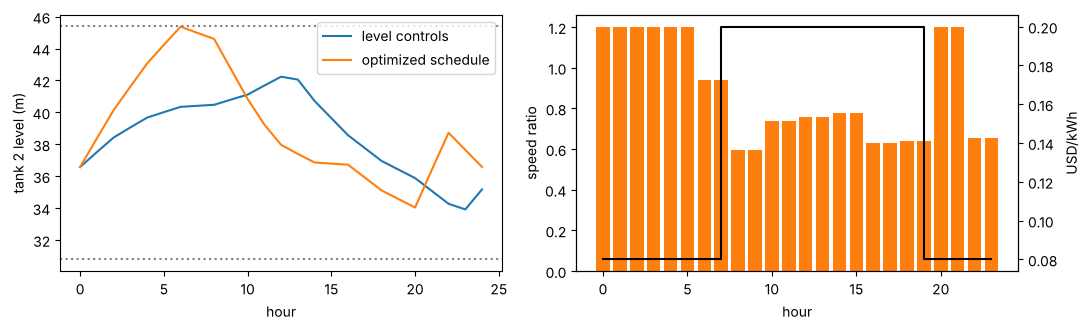

In [4]:
opt = simulate(net, sched_free, model=model, speed_profile=profile(jnp.asarray(res.x)), profile_step=block)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(base["time"] / 3600, np.asarray(base["tank_level"])[:, 0], label="level controls")
ax[0].plot(opt["time"] / 3600, np.asarray(opt["tank_level"])[:, 0], label="optimized schedule")
for v in (lo, hi):
    ax[0].axhline(v, color="gray", ls=":")
ax[0].set_xlabel("hour"); ax[0].set_ylabel("tank 2 level (m)"); ax[0].legend()
hours = np.arange(24)
ax[1].bar(hours, np.repeat(res.x, 2), color="C1", label="pump speed")
ax2 = ax[1].twinx(); ax2.step(hours, price(hours * 3600.0), where="post", color="k", label="tariff")
ax[1].set_xlabel("hour"); ax[1].set_ylabel("speed ratio"); ax2.set_ylabel("USD/kWh")
plt.tight_layout()

The schedule fills the tank at full speed in the cheap night hours, up to the top of its band by hour 6, and runs the pump slower through the expensive day, ending the day where it started. SLSQP's message says it stopped where its line search could make no progress: this is a local stop, not a certified optimum. The problem is non-convex: below a certain speed the pump cannot lift water into the network at all, so cost and levels stop depending on the speed (flat regions with zero gradient), and on/off-like schedules are separated by those flats. With the smooth valve formulation (`smoothing=1e-2`) the same start ended at a worse point (about 154 USD), so the smoothing does not remove this difficulty; other starting points, or a mixed-integer on/off formulation, are the next things to try if a better schedule matters.

## Notes

- The derivatives hold the sequence of discrete events fixed (no tank reaching a limit, here kept away by the band); each SLSQP evaluation re-runs the day, so the plan follows the schedule.
- A real schedule also weighs pump wear (number of starts), demand charges and uncertain demand; the speed bounds stand in for a variable-speed drive's range.
- Energy is `rho g Q h / efficiency` with EPANET's global 75 % efficiency from the input file.